# FedCircuitNet - Training vs. Test Loss, multiple tags

Multi-run version of `show_loss.ipynb`. For a **list of run tags** (`TAGS`), it draws **one compact figure with one row per tag**; each row is the couple of plots from `show_loss.ipynb`:

1. **Training loss per step** - `Mean Client Train Loss`, one point per FL round.
2. **Test loss per sample** - `Test Loss (dist)`, one point per test sample.

The two plots of a couple are glued together (shared y-axis within the row, almost no gap) and rows are stacked tightly, so many runs fit in a small figure. The last section prints the same figure as a standalone pgfplots `groupplot` (`group size=2 by N`), ready to copy-paste.

Everything is read from the local Aim repository (`aim.Repo(path=os.getcwd())`), same convention as `show_loss.ipynb`.

In [1]:
import os

import numpy as np
import matplotlib.pyplot as plt

from aim import Repo
from aim.storage.context import Context

repo = Repo(path=os.getcwd())

TRAIN_EXPERIMENTS = [
    'fedavg_drc_train_20261012',
]

TEST_EXPERIMENTS = [
    'fedavg_drc_test_20261012',
]

In [2]:
def get_runs_by_experiment_name(experiment_name):
    query = (
        'run.active == False and run.archived == False '
        f'and run.experiment == "{experiment_name}"'
    )
    return list(repo.query_runs(query=query, report_mode=0).iter_runs())


def collect_runs(experiment_names):
    """Flatten runs across a list of experiment names, deduped by hash."""
    seen = set()
    runs = []
    for name in experiment_names:
        for wrapper in get_runs_by_experiment_name(name):
            r = wrapper.run
            if r.hash in seen:
                continue
            seen.add(r.hash)
            runs.append(r)
    return runs


def train_scheme_tag(run):
    """Run ID of a train run, from `training.save_path` (.../fedavg_<ID>)."""
    hparams = run.get('hparams') or {}
    save_path = (hparams.get('training') or {}).get('save_path') or ''
    folder = os.path.basename(os.path.normpath(save_path)) if save_path else ''
    if folder.startswith('fedavg_'):
        return folder[len('fedavg_'):]
    return folder or run.hash


def test_scheme_tag(run):
    """Run ID of a test run, from the checkpoint dir (.../fedavg_<ID>/model_round_<T>.pth)."""
    hparams = run.get('hparams') or {}
    checkpoint = hparams.get('checkpoint') or ''
    parent = os.path.basename(os.path.dirname(checkpoint)) if checkpoint else ''
    if parent.startswith('fedavg_'):
        return parent[len('fedavg_'):]
    return parent or run.hash


def metric_series_with_steps(run, name, context=None):
    """Return (steps, values) sorted by step for the given metric."""
    metric = run.get_metric(name, context=Context(context or {}))
    if metric is None:
        return np.array([]), np.array([])

    steps = metric.timestamps.values_numpy()
    vals = metric.values.values_numpy()
    idx = np.argsort(steps)
    return np.sort(idx), vals[idx]


def per_sample_metric(run, name, context=None):
    """Raw per-sample values tracked for `name` (insertion order)."""
    metric = run.get_metric(name, context=Context(context or {}))
    return metric.values.values_numpy() if metric is not None else np.array([])

## Available run tags

In [3]:
train_runs_all = collect_runs(TRAIN_EXPERIMENTS)
test_runs_all = collect_runs(TEST_EXPERIMENTS)

print('Train tags:', sorted({train_scheme_tag(r) for r in train_runs_all}))
print('Test tags: ', sorted({test_scheme_tag(r) for r in test_runs_all}))

Train tags: ['40KLiid_c10', '40KLiid_c20', '40KLiid_c5', 'FH_40KL_c10', 'FH_40KL_c20', 'FH_40KL_c5']
Test tags:  ['40KLiid_c10', '40KLiid_c20', '40KLiid_c5', 'FH_40KL_c10', 'FH_40KL_c20', 'FH_40KL_c5']


## Pick the runs and load their data

`TAGS` sets the row order (top to bottom). Tags missing a train or test run, or a metric, are skipped with a warning.

In [4]:
# <-- tags to merge in the figure (top to bottom)
TAGS = ['FH_40KL_c5', 'FH_40KL_c10', 'FH_40KL_c20', '40KLiid_c5', '40KLiid_c10', '40KLiid_c20']


# couples (train+test) placed side by side on the horizontal axis (2-3 is a good range)
N_COLS = 2

data = {}  # tag -> dict(train_x, train_y, test_x, test_y, loss_label)
for tag in TAGS:
    train_run = next((r for r in train_runs_all if train_scheme_tag(r) == tag), None)
    test_run = next((r for r in test_runs_all if test_scheme_tag(r) == tag), None)
    if train_run is None or test_run is None:
        print(f'[{tag}] SKIPPED: missing {"train" if train_run is None else "test"} run')
        continue

    train_x, train_y = metric_series_with_steps(
        train_run, 'Mean Client Train Loss', context={'subset': 'train'}
    )
    test_y = per_sample_metric(
        test_run, 'Test Loss (dist)', context={'subset': 'test', 'aggregation': 'distribution'}
    )
    if train_y.size == 0 or test_y.size == 0:
        print(f'[{tag}] SKIPPED: no train loss ({train_y.size} pts) or test loss ({test_y.size} pts)')
        continue

    train_strategy = (train_run.get('hparams') or {}).get('strategy') or {}
    test_strategy = (test_run.get('hparams') or {}).get('strategy') or {}
    if train_strategy.get('loss_type') != test_strategy.get('loss_type'):
        print(f'[{tag}] WARNING: train/test loss_type mismatch')

    data[tag] = dict(
        train_x=train_x, train_y=train_y,
        test_x=np.arange(test_y.size), test_y=test_y,
        loss_label=train_strategy.get('loss_type', 'loss'),
    )
    print(f'[{tag}] loaded: {train_y.size} train points, {test_y.size} test points')

[FH_40KL_c5] loaded: 1600 train points, 3164 test points
[FH_40KL_c10] loaded: 1600 train points, 3164 test points
[FH_40KL_c20] loaded: 1600 train points, 3164 test points
[40KLiid_c5] loaded: 1600 train points, 3164 test points
[40KLiid_c10] loaded: 1600 train points, 3164 test points
[40KLiid_c20] loaded: 1600 train points, 3164 test points


## Compact figure: couples of plots on a grid

Each tag is a couple: left = training loss per round, right = test loss per sample. The couples are laid out on a grid with `N_COLS` couples per row (filled left to right, then top to bottom). Inside a couple the y-axis is shared and the gap is tiny; between couples there is a wider gap and rows are stacked tightly. The left y-label is the tag.

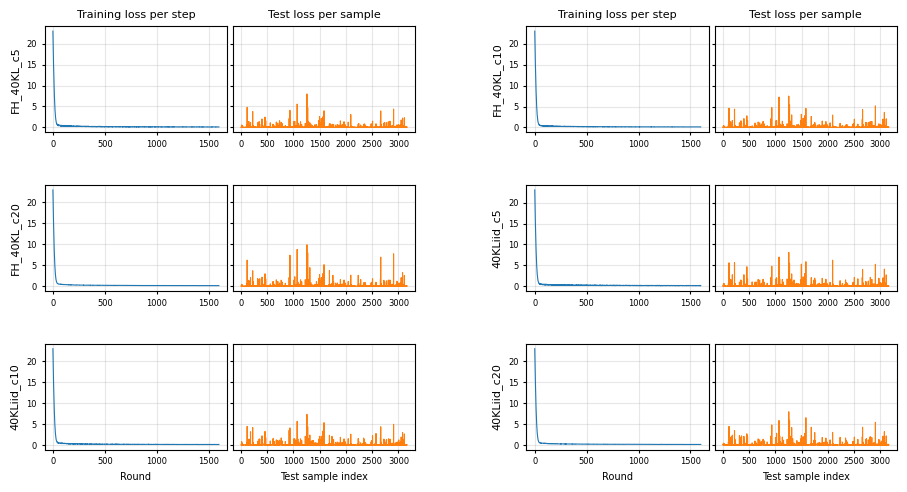

In [5]:
import math
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec

if not data:
    raise ValueError('No tag has data - check TAGS / the available tags above.')

n = len(data)
n_rows = math.ceil(n / N_COLS)
fig = plt.figure(figsize=(5.5 * N_COLS, 1.7 * n_rows + 0.4))
outer = GridSpec(n_rows, N_COLS, figure=fig, wspace=0.3, hspace=0.5)

for k, (tag, d) in enumerate(data.items()):
    r, c = divmod(k, N_COLS)
    inner = GridSpecFromSubplotSpec(1, 2, subplot_spec=outer[r, c], wspace=0.03)
    ax_tr = fig.add_subplot(inner[0])
    ax_te = fig.add_subplot(inner[1], sharey=ax_tr)
    ax_te.tick_params(labelleft=False)
    ax_tr.plot(d['train_x'], d['train_y'], color='tab:blue', lw=0.8)
    ax_te.plot(d['test_x'], d['test_y'], color='tab:orange', lw=0.8)
    ax_tr.set_ylabel(tag, fontsize=8)
    for ax in (ax_tr, ax_te):
        ax.grid(True, alpha=0.3)
        ax.tick_params(labelsize=6, length=2)
    if r == 0:
        ax_tr.set_title('Training loss per step', fontsize=8)
        ax_te.set_title('Test loss per sample', fontsize=8)
    if k + N_COLS >= n:  # nothing below this couple
        ax_tr.set_xlabel('Round', fontsize=7)
        ax_te.set_xlabel('Test sample index', fontsize=7)

plt.show()
plt.close(fig)

## LaTeX export (pgfplots `groupplot`)

Prints the figure above as a complete `standalone` document. Each couple is its own `groupplot` (`group size=2 by 1`, `horizontal sep=1cm`, same explicit `ymin`/`ymax` on both plots = same scale), and the couples are placed on a grid of `N_COLS` couples per row with absolute `at={...}` positions (`COL_STEP_CM` / `ROW_STEP_CM` set the spacing, tune them if labels collide). Only the first row has titles, couples with nothing below have the x labels, and the left y label is the tag.

To keep the `.tex` small, each curve is reduced to at most `MAX_POINTS_TRAIN` / `MAX_POINTS_TEST` points: consecutive points are split into equal groups and each group is replaced by its mean. Run the data cell first.

In [6]:
# max number of points written to the LaTeX output for each curve
MAX_POINTS_TRAIN = 100
MAX_POINTS_TEST = 100

# distance between couples on the grid (cm): column step ~ 2 plots + inner sep + y labels + gap
COL_STEP_CM = 7
ROW_STEP_CM = 1.8


def group_mean(xs, ys, max_points):
    # split the series into <= max_points consecutive groups, replace each by its mean
    xs, ys = np.asarray(xs, dtype=float), np.asarray(ys, dtype=float)
    if xs.size <= max_points:
        return xs, ys
    xg = np.array_split(xs, max_points)
    yg = np.array_split(ys, max_points)
    return (np.array([g.mean() for g in xg]), np.array([g.mean() for g in yg]))


def _coords(xs, ys):
    return '\n'.join(f'            ({x:.6g}, {y:.6g})' for x, y in zip(xs, ys))


def latex_escape(text):
    return str(text).replace('_', r'\_')


def build_groupplot(data, n_cols):
    # return a full standalone document (compile as-is with pdflatex)
    # NB: no %-formatting here, the literal `%` of the LaTeX comments would clash with it
    n = len(data)
    lines = [
        r'\documentclass[border=5pt]{standalone}',
        r'\usepackage{pgfplots}',
        r'\usepgfplotslibrary{groupplots}',
        r'\pgfplotsset{compat=1.16}',
        r'\definecolor{onehot}{HTML}{2A7BDE}',
        r'\definecolor{categ}{HTML}{F26B30}',
        r'\begin{document}',
        r'\begin{tikzpicture}',
        r'\pgfplotsset{small legend/.style={',
        r'legend style={font=\fontsize{4}{4}\selectfont, draw=none, fill=white, fill opacity=0.8,',
        r'inner sep=0.5pt, row sep=-3pt,',
        r'legend image post style={xscale=0.4},',
        r'at={(0.03,0.97)}, anchor=north west},',
        r'legend cell align=left}}',
    ]
    for k, (tag, d) in enumerate(data.items()):
        r, c = divmod(k, n_cols)
        tx, ty = group_mean(d['train_x'], d['train_y'], MAX_POINTS_TRAIN)
        sx, sy = group_mean(d['test_x'], d['test_y'], MAX_POINTS_TEST)
        lo, hi = min(ty.min(), sy.min()), max(ty.max(), sy.max())
        pad = 0.05 * (hi - lo) if hi > lo else 1.0
        ylim = f'ymin={lo - pad:.6g}, ymax={hi + pad:.6g},'

        # legend stats are computed on the full (non-grouped) series
        train_legend = f"final $= {d['train_y'][-1]:.4g}$"
        test_legend = f"$\\mu = {d['test_y'].mean():.4g}$, $\\sigma = {d['test_y'].std():.4g}$"

        left = [f'ylabel={{{latex_escape(tag)}}},']
        right = []
        if r == 0:
            left.append(r'title={Training loss per step},')
            right.append(r'title={Test loss per sample},')
        if k + n_cols >= n:  # nothing below this couple
            left.append(r'xlabel={Round},')
            right.append(r'xlabel={Test sample index},')

        lines += [
            '',
            f'    % --- {latex_escape(tag)}: {tx.size} train / {sx.size} test points ---',
            f'    \\begin{{scope}}[shift={{({c * COL_STEP_CM:.4g}cm, {-r * ROW_STEP_CM:.4g}cm)}}]',
            r'    \begin{groupplot}[',
            r'        group style={',
            r'            group size=2 by 1,',
            r'            horizontal sep=0.5cm,',
            r'        },',
            r'        width=4cm,',
            r'        height=2.6cm,',
            r'        grid=major,',
            r'        grid style={opacity=0.3},',
            r'        enlarge y limits=false,',
            f'        {ylim}',
            r'        tick label style={font=\tiny},',
            r'        label style={font=\scriptsize},',
            r'        title style={font=\scriptsize},',
            r'        small legend',
            r'    ]',
            r'    \nextgroupplot[', *[f'        {o}' for o in left], r'    ]',
            r'        \addplot[onehot, thick] coordinates {', _coords(tx, ty), r'        };',
            f'        \\addlegendentry{{{train_legend}}}',
            r'    \nextgroupplot[', *[f'        {o}' for o in right], r'    ]',
            r'        \addplot[categ, thick] coordinates {', _coords(sx, sy), r'        };',
            f'        \\addlegendentry{{{test_legend}}}',
            r'    \end{groupplot}',
            r'    \end{scope}',
        ]
    lines += ['', r'\end{tikzpicture}', r'\end{document}']
    return '\n'.join(lines)


if not data:
    print('No data - run the data cell first / check TAGS.')
else:
    print(build_groupplot(data, N_COLS))

\documentclass[border=5pt]{standalone}
\usepackage{pgfplots}
\usepgfplotslibrary{groupplots}
\pgfplotsset{compat=1.16}
\definecolor{onehot}{HTML}{2A7BDE}
\definecolor{categ}{HTML}{F26B30}
\begin{document}
\begin{tikzpicture}
\pgfplotsset{small legend/.style={
legend style={font=\fontsize{4}{4}\selectfont, draw=none, fill=white, fill opacity=0.8,
inner sep=0.5pt, row sep=-3pt,
legend image post style={xscale=0.4},
at={(0.03,0.97)}, anchor=north west},
legend cell align=left}}

    % --- FH\_40KL\_c5: 100 train / 100 test points ---
    \begin{scope}[shift={(0cm, 0cm)}]
    \begin{groupplot}[
        group style={
            group size=2 by 1,
            horizontal sep=0.5cm,
        },
        width=4cm,
        height=2.6cm,
        grid=major,
        grid style={opacity=0.3},
        enlarge y limits=false,
        ymin=-0.702439, ymax=14.8574,
        tick label style={font=\tiny},
        label style={font=\scriptsize},
        title style={font=\scriptsize},
        small legend